## Install

In a `virtualenv`/`conda`/`uv`-managed environment, create/activate the environment first and then install from the repository

```bash
pip install git+https://github.com/cellgeni/spatialdata-dissect
```

## Load the dataset into SpatialData


In [9]:
import spatialdata
import spatialdata_io
import spatialdata_dissect

import warnings
warnings.filterwarnings("ignore", category=UserWarning)

sdata = spatialdata_io.xenium("/nfs/team172_spatial_genomics_imaging/2025_Requests/SGP221 COPD lung Xenium/20250210__164750__SGP221_RUN2/output-XETG00155__0044032__330_CO-ES_RLL-S4_331_CO-ES_RUL-S4__20250210__164932")
sdata

SpatialData object
├── Images
│     └── 'morphology_focus': DataTree[cyx] (4, 23892, 39784), (4, 11946, 19892), (4, 5973, 9946), (4, 2986, 4973), (4, 1493, 2486)
├── Labels
│     ├── 'cell_labels': DataTree[yx] (23892, 39784), (11946, 19892), (5973, 9946), (2986, 4973), (1493, 2486)
│     └── 'nucleus_labels': DataTree[yx] (23892, 39784), (11946, 19892), (5973, 9946), (2986, 4973), (1493, 2486)
├── Points
│     └── 'transcripts': DataFrame with shape: (2877011, 13) (3D points)
├── Shapes
│     ├── 'cell_boundaries': GeoDataFrame shape: (31468, 1) (2D shapes)
│     └── 'nucleus_boundaries': GeoDataFrame shape: (31353, 2) (2D shapes)
└── Tables
      └── 'table': AnnData (31468, 341)
with coordinate systems:
    ▸ 'global', with elements:
        morphology_focus (Images), cell_labels (Labels), nucleus_labels (Labels), transcripts (Points), cell_boundaries (Shapes), nucleus_boundaries (Shapes)

## Run `spatialdata_dissect` on the data

The defaults work for many Xenium morphology images. The policy below limits the maximum number of pieces for a compact demo.

The overview figure shows:
- **cyan**: bounding boxes
- **green**: tissue assigned to the box
- **red**: neighbouring tissue that would be subtracted from that box

Wrote overview + 5 crop(s) to preview_out


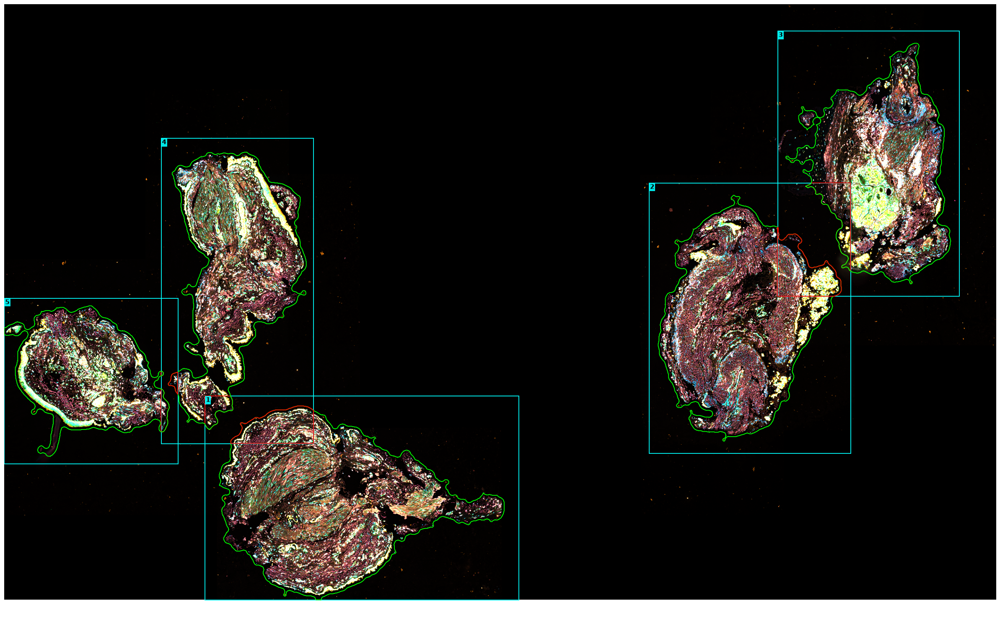

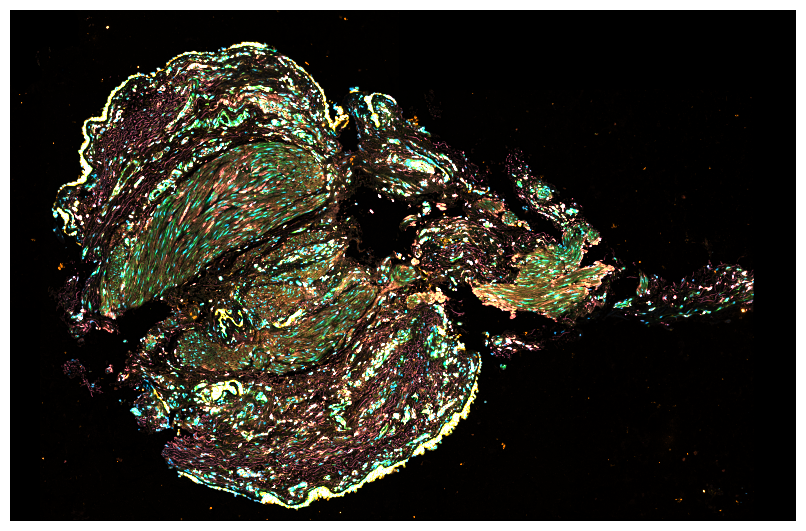

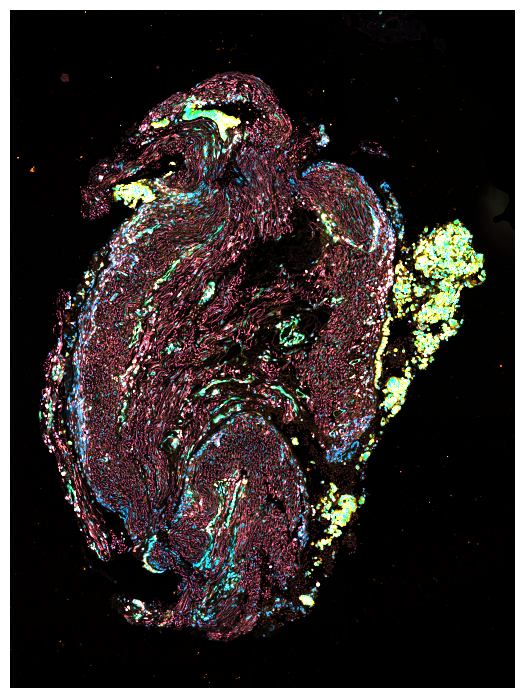

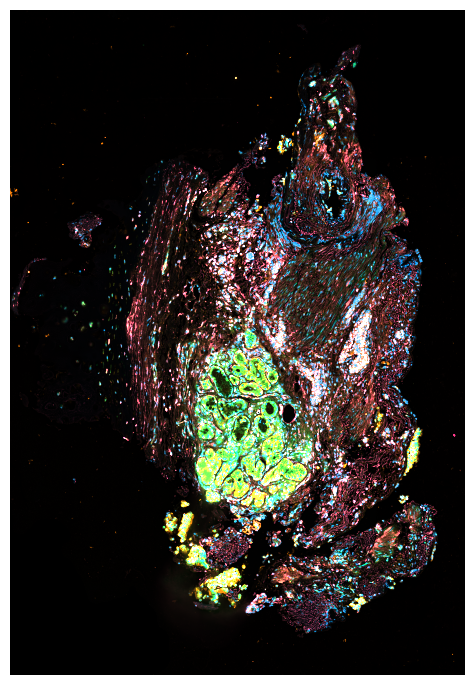

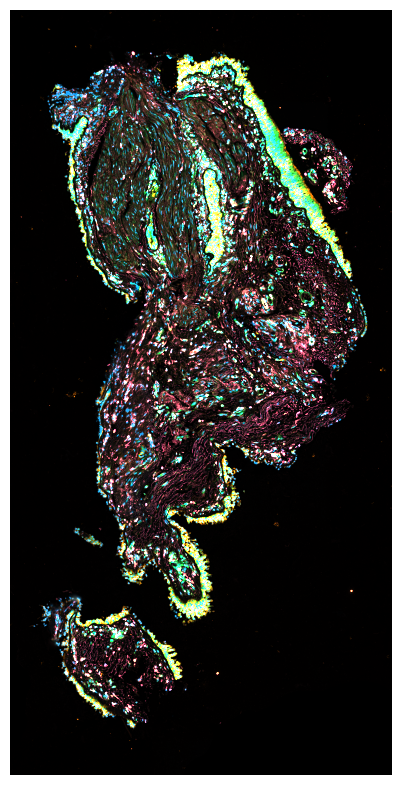

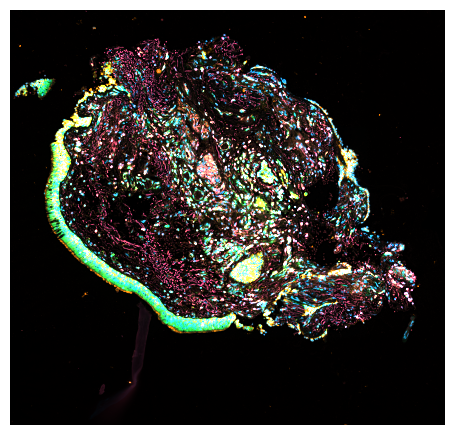

In [13]:
boxes = spatialdata_dissect.detect_tissue(sdata, image_key="morphology_focus")

overview_fig, _ = spatialdata_dissect.preview_detection(
    sdata, 
    boxes, 
    image_key="morphology_focus", 
    dpi=100, 
    outdir="preview_out",
);


## Merge boxes

Merge multiple boxes into one. In this example we'll merge the tissues on each cluster together.

In [3]:
boxes_merged = spatialdata_dissect.merge_boxes(boxes, [ [1, 4, 5], [2, 3] ])


Wrote overview + 2 crop(s) to merged_out


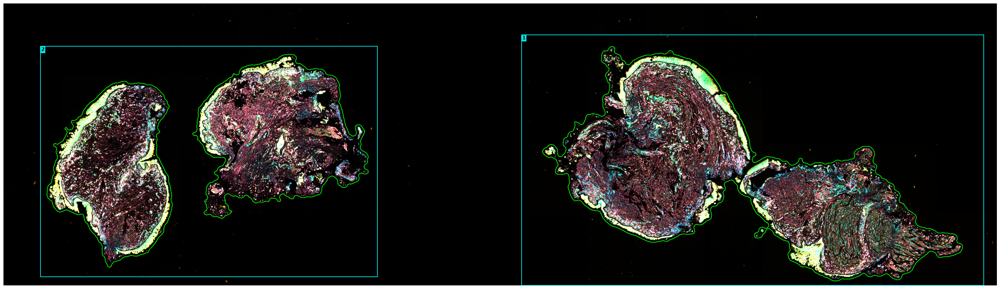

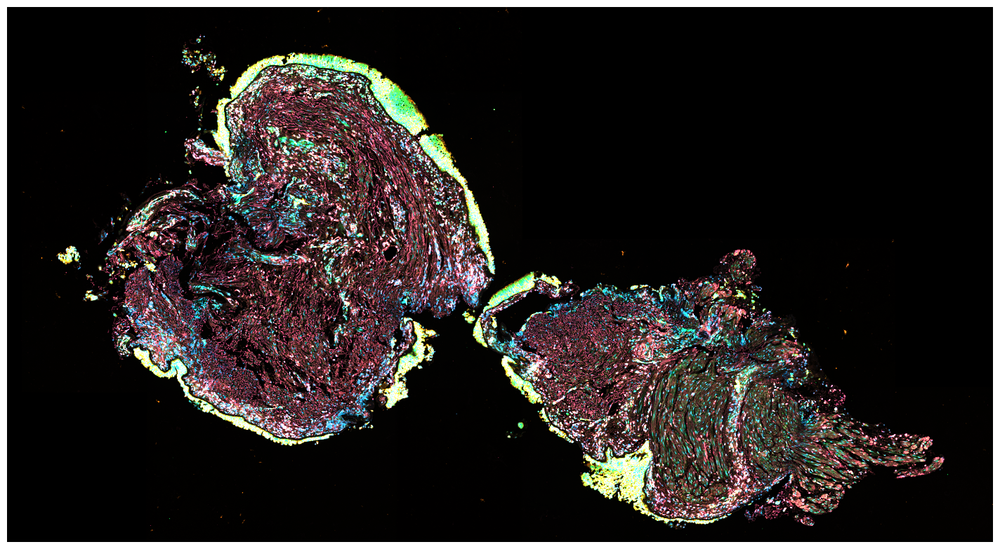

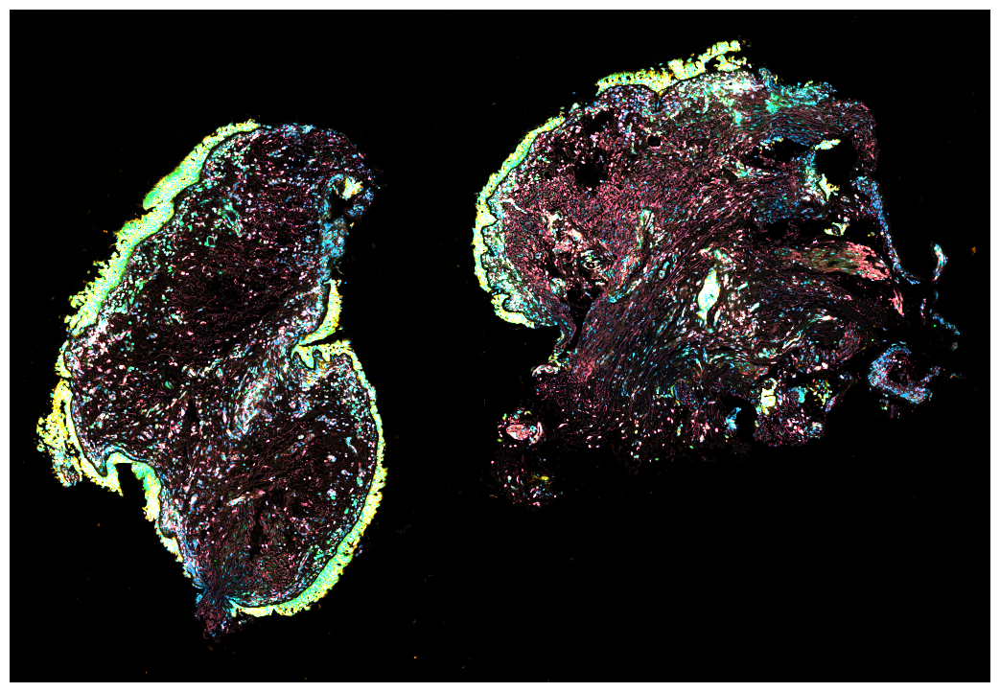

In [4]:
merged_overview_fig, merged_crop_figs = spatialdata_dissect.preview_detection(
    sdata,
    boxes_merged,
    image_key="morphology_focus",
    dpi=100,
    outdir="merged_out"
)

## Get polygons for the bounding boxes

In [5]:
polygons = spatialdata_dissect.get_dissected_boxes(
    sdata, 
    boxes_merged, 
    overlap="minus", 
    transformation="global", 
    image_key="morphology_focus"
)

for i, poly in enumerate(polygons, start=1):
    print(f"Box {i}: {poly.geom_type}, area={poly.area:,.2f}, bounds={tuple(round(v, 2) for v in poly.bounds)}")
    

Box 1: Polygon, area=274,305,941.24, bounds=(25172.17, 1520.11, 47639.89, 13729.0)
Box 2: Polygon, area=183,889,238.46, bounds=(1792.3, 2080.15, 18163.01, 13312.97)


## Use polygons to split SpatialData object

In [6]:
dissected = []
for i, poly in enumerate(polygons, start=1):
    
    sdata_crop = spatialdata.polygon_query(
        sdata, 
        polygon=poly, 
        target_coordinate_system="global", 
        filter_table=True
    )
    
    dissected.append(sdata_crop)


In [7]:
print(dissected)

[SpatialData object
├── Images
│     └── 'morphology_focus': DataTree[cyx] (4, 12209, 22468), (4, 6104, 11234), (4, 3052, 5617), (4, 1526, 2808), (4, 763, 1404)
├── Labels
│     ├── 'cell_labels': DataTree[yx] (12209, 22468), (6104, 11234), (3052, 5617), (1526, 2808), (763, 1404)
│     └── 'nucleus_labels': DataTree[yx] (12209, 22468), (6104, 11234), (3052, 5617), (1526, 2808), (763, 1404)
├── Points
│     └── 'transcripts': DataFrame with shape: (<Delayed>, 13) (3D points)
├── Shapes
│     ├── 'cell_boundaries': GeoDataFrame shape: (20165, 1) (2D shapes)
│     └── 'nucleus_boundaries': GeoDataFrame shape: (20248, 2) (2D shapes)
└── Tables
      └── 'table': AnnData (20165, 341)
with coordinate systems:
    ▸ 'global', with elements:
        morphology_focus (Images), cell_labels (Labels), nucleus_labels (Labels), transcripts (Points), cell_boundaries (Shapes), nucleus_boundaries (Shapes), SpatialData object
├── Images
│     └── 'morphology_focus': DataTree[cyx] (4, 11233, 16371), (4, 

## Preview the cropped SpatialData object

This cell uses `spatialdata-plot` if it is available. If plotting fails because the object is very large or the plotting API changes, the saved `.zarr` output in the next cell is still the main result.

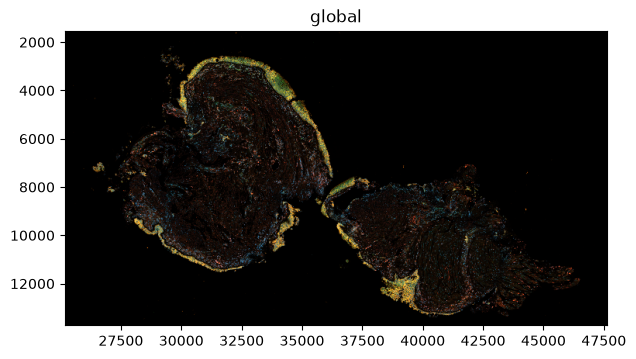

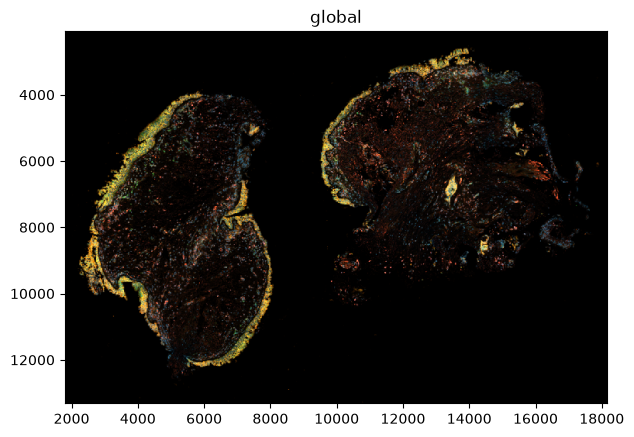

In [8]:
import spatialdata_plot
import matplotlib.pyplot as plt

for sd in dissected:
    fig, ax = plt.subplots(figsize=(7, 7))
    sd.pl.render_images().pl.show(ax=ax)